In [1]:
import random, time, math, copy
from collections import deque
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torch.distributions import Categorical, Normal
import gymnasium as gym

In [2]:
SEED = 2026
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

if torch.cuda.is_available():
    DEVICE = torch.device('cuda')
elif torch.backends.mps.is_available():
    DEVICE = torch.device('mps')
elif torch.xpu.is_available():
    DEVICE = torch.device('xpu')
else:
    DEVICE = torch.device('cpu')

print(DEVICE)

cpu


In [3]:
class DiscreteActorCritic(nn.Module):
    def __init__(self, obs_dim=4, n_actions=2, hidden=128):
        super().__init__()
        self.body = nn.Sequential(
            nn.Linear(obs_dim, hidden), nn.Tanh(),
            nn.Linear(hidden, hidden), nn.Tanh()
        )
        self.actor = nn.Linear(hidden, n_actions)
        self.critic = nn.Linear(hidden, 1)

    def forward(self, states):
        features = self.body(states)
        logits = self.actor(features)
        values = self.critic(features).squeeze(-1)
        return logits, values

net_test = DiscreteActorCritic().to(DEVICE)
logits, values = net_test(torch.zeros(4, 4, device=DEVICE))
print('logits:', logits.shape, 'values:', values.shape)

logits: torch.Size([4, 2]) values: torch.Size([4])


___
### **1-4-5. A2C 학습 과정 구현 실습**
1. 환경 N개 만들고 상태 모으기
2. T번 반복하면서 같은 정책으로 각 환경의 행동 선택
3. 보상, 종료 여부, 가치, 행동 로그확률, 엔트로피 저장하기
4. 각 환경 종료되면 다음 에피소드로 리셋. 단 종료 전 마지막 관측에서 계산한 부트스트랩 가치를 보존할 것
5. 역순으로 n-step Return 계산하기
6. Actor / Critic / Entropy 손실 합산하고 optimizer.step() 호출해서 기울기 수정
> 위 내용을 넣은 training loop 작성하기

In [11]:
import time
import koreanize_matplotlib

In [12]:
# seed 설정 함수
def set_seed(seed=2026):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

In [13]:
# 기존 Actor-Critic 코드를 A2C 방식으로 수정해봄
# num_envs: 동시에 경험을 수집할 환경 개수 N
# rollout_steps: 업데이트 전 환경마다 수집할 스텝 수 T
# updates: 전체 신경망 업데이트 횟수
def train_a2c(
        updates=500, seed=2026, gamma=0.99,lr=3e-4, hidden=128, num_envs=4, rollout_steps=25, critic_coef=0.5, entropy_coef=0.01, print_every=50):

    set_seed(seed)

    # 1. 환경 N개 만들고 상태 모으기
    envs = [
        gym.make("CartPole-v1")
        for _ in range(num_envs)
    ]

    states = []
    for i, env in enumerate(envs):
        env.action_space.seed(seed + i)
        state, _ = env.reset(seed=seed + i)
        states.append(state)

    states = np.stack(states)

    # ActorCriticNet > DiscreteActorCritic 변경
    model = DiscreteActorCritic(obs_dim=4, n_actions=2, hidden=hidden).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    scores, lengths = [], []
    actor_losses, critic_losses, entropies = [], [], []
    current_scores = np.zeros(num_envs)
    current_lengths = np.zeros(num_envs, dtype=int)
    start = time.time()

    try:
        for update in range(updates):

            # 3. T스텝 동안 수집한 경험 저장
            rewards_buf = []
            dones_buf = []
            logps_buf = []
            values_buf = []
            entropies_buf = []
            bootstrap_buf = []

            # 2. T번 반복하며 같은 정책으로 각 환경의 행동 선택
            for t in range(rollout_steps):

                x = torch.as_tensor(
                    states, dtype=torch.float32, device=DEVICE
                )

                logits, value = model(x)
                dist = Categorical(logits=logits)
                action = dist.sample()

                # 가치, 로그확률, 엔트로피 저장
                values_buf.append(value)
                logps_buf.append(dist.log_prob(action))
                entropies_buf.append(dist.entropy())

                next_states = []
                rewards = []
                dones = []
                bootstrap_values = torch.zeros(
                    num_envs, dtype=torch.float32, device=DEVICE
                )

                for i, env in enumerate(envs):

                    next_state, reward, terminated, truncated, _ = env.step(
                        int(action[i].item())
                    )

                    done = terminated or truncated

                    rewards.append(float(reward))
                    dones.append(done)

                    current_scores[i] += float(reward)
                    current_lengths[i] += 1

                    # 4. 종료되기 전 마지막 관측으로 부트스트랩 가치 계산
                    # 진짜 종료(terminated)는 다음 가치가 0
                    # 시간 제한 종료(truncated)는 마지막 상태의 가치를 사용
                    if truncated and not terminated:
                        with torch.no_grad():
                            nx = torch.as_tensor(
                                next_state,
                                dtype=torch.float32,
                                device=DEVICE
                            ).unsqueeze(0)

                            _, next_value = model(nx)
                            bootstrap_values[i] = next_value.item()

                    # 환경 종료 시 다음 에피소드 시작
                    if done:
                        scores.append(float(current_scores[i]))
                        lengths.append(int(current_lengths[i]))

                        current_scores[i] = 0.0
                        current_lengths[i] = 0

                        next_state, _ = env.reset()

                    next_states.append(next_state)

                rewards_buf.append(
                    torch.as_tensor(
                        rewards, dtype=torch.float32, device=DEVICE
                    )
                )
                dones_buf.append(
                    torch.as_tensor(dones, dtype=torch.bool, device=DEVICE)
                )
                bootstrap_buf.append(bootstrap_values)

                states = np.stack(next_states)

            # T스텝 이후 마지막 상태의 가치 계산
            with torch.no_grad():
                nx = torch.as_tensor(
                    states, dtype=torch.float32, device=DEVICE
                )
                _, next_value = model(nx)

            # 5. 역순으로 n-step Return 계산
            returns_buf = []

            for t in reversed(range(rollout_steps)):

                # 종료된 환경은 다음 에피소드의 가치가 섞이지 않도록 처리
                next_value = torch.where(
                    dones_buf[t],
                    bootstrap_buf[t],
                    next_value
                )

                td_target = rewards_buf[t] + gamma * next_value
                returns_buf.insert(0, td_target)
                next_value = td_target

            returns = torch.stack(returns_buf).detach()
            values = torch.stack(values_buf)
            logps = torch.stack(logps_buf)
            entropies_tensor = torch.stack(entropies_buf)

            # Advantage = n-step Return - Critic의 예측 가치
            delta = returns - values

            # 6. Actor / Critic / Entropy 손실 계산
            actor_loss = -(logps * delta.detach()).mean()
            critic_loss = F.mse_loss(values, returns)
            entropy = entropies_tensor.mean()

            loss = (
                actor_loss
                + critic_coef * critic_loss
                - entropy_coef * entropy
            )

            # 손실을 이용해 모델 학습 (T스텝마다 1회)
            optimizer.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()

            # 학습 통계 기록
            actor_losses.append(float(actor_loss.item()))
            critic_losses.append(float(critic_loss.item()))
            entropies.append(float(entropy.item()))

            if print_every and (update + 1) % print_every == 0:
                recent = (
                    np.mean(scores[-50:]) if scores else float("nan")
                )

                print(
                    f"A2C {update+1:4d}/{updates} | "
                    f"최근 50회 평균 {recent:8.2f} | "
                    f"완료 에피소드 {len(scores)} | "
                    f"{time.time()-start:.0f}s"
                )

    finally:
        for env in envs:
            env.close()

    history = pd.DataFrame({
        "episode": np.arange(1, len(scores) + 1),
        "reward": scores,
        "steps": lengths
    })

    loss_history = pd.DataFrame({
        "update": np.arange(1, len(actor_losses) + 1),
        "actor_loss": actor_losses,
        "critic_loss": critic_losses,
        "entropy": entropies
    })

    return model, history, loss_history


In [8]:
# 학습 실행
a2c_model, a2c_history, a2c_loss_history = train_a2c(
    updates=500,
    seed=2026,
    gamma=0.99,
    lr=3e-4,
    num_envs=4,
    rollout_steps=25,
    entropy_coef=0.01
)

print(a2c_history.tail())

A2C   50/500 | 최근 50회 평균    30.02 | 완료 에피소드 166 | 1s
A2C  100/500 | 최근 50회 평균    32.88 | 완료 에피소드 336 | 4s
A2C  150/500 | 최근 50회 평균    24.40 | 완료 에피소드 529 | 5s
A2C  200/500 | 최근 50회 평균    24.40 | 완료 에피소드 727 | 7s
A2C  250/500 | 최근 50회 평균    27.94 | 완료 에피소드 899 | 9s
A2C  300/500 | 최근 50회 평균    36.32 | 완료 에피소드 1054 | 10s
A2C  350/500 | 최근 50회 평균    40.08 | 완료 에피소드 1180 | 13s
A2C  400/500 | 최근 50회 평균    36.76 | 완료 에피소드 1313 | 15s
A2C  450/500 | 최근 50회 평균    44.84 | 완료 에피소드 1429 | 17s
A2C  500/500 | 최근 50회 평균    55.50 | 완료 에피소드 1518 | 20s
      episode  reward  steps
1513     1514    67.0     67
1514     1515    78.0     78
1515     1516    52.0     52
1516     1517    33.0     33
1517     1518    37.0     37


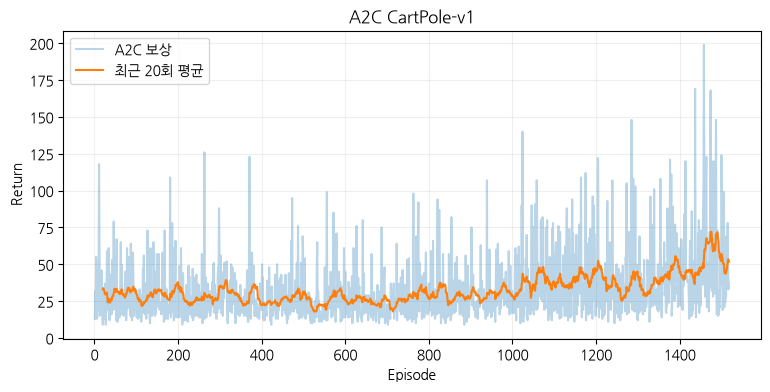

In [14]:
# 시각화
plt.figure(figsize=(9, 4))

plt.plot(
    a2c_history["episode"],
    a2c_history["reward"],
    alpha=0.3,
    label="A2C 보상"
)

plt.plot(
    a2c_history["episode"],
    a2c_history["reward"].rolling(20).mean(),
    label="최근 20회 평균"
)

plt.xlabel("Episode")
plt.ylabel("Return")
plt.title("A2C CartPole-v1")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

#### 결과 해석
```
파란색 : 에피소드별 보상
주황색 : 최근 20회 평균 보상 (전체적인 학습 성능 변화)
초반 (0~500)    : 낮은 보상 (평균 약 25~35)
중반 (500~1000) : 크게 개선없어보임 정체된 것 같음 (평균 약 25~40)
후반 (1000~)    : 평균보상 좀 높아짐 (평균 약 35~70)
```
- A2C 학습으로 성능을 개선하는 것 처럼 보이긴 하지만, 안정적으로 정책을 학습했다고 보긴 어려움
- 학습이 진행되긴 함 > 평균 보상이 증가했으니까
- 높은 보상을 얻는 에피소드 나온것 확인함 > 후반에 일부 에피소드에서 150~200점 가까이 나옴(= 높은 보상을 얻는 행동 가능하다는거)
- 하지만 전체적으로 보면 여전히 학습 불안정함 
    - 파란색 그래프는 후반에도 상승 하락 폭이 크고, 주황색 평균 보상도 비슷하게 상승과 하락 반복함
    - 그래서 성능이 개선되긴 하지만, 매번 높은 보상을 안정적으로 얻는 수준까지 학습하진 못함
